# Introduction to Quantitative Biology — Lecture 3
## Stability and positive autoregulation

*Luca Ciandrini — luca.ciandrini@umontpellier.fr*

In Lecture 2 a gene that represses itself turned out to be fast and robust. Today the gene
**activates** itself, and we look at it with the tool of the pre-read: production and removal
drawn against $X$.

1. **Section 1.** The rate plot, turned into a function we can reuse.
2. **Section 2.** How fast a stable point pulls $X$ back --- and why self-repression is fast and
   self-activation slow.
3. **Section 3.** Self-activation with $n = 1$ and with $n = 4$: one steady state, or two.
4. **Section 4.** What two steady states are good for: memory.

Everything today is deterministic: $X$ is a concentration and follows $dX/dt = f(X) - \alpha X$.

**How to use it.** Before running a cell marked **PREDICT**, write down what you expect.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

BLUE, CORAL, INK, GREY = "#008AAE", "#F06E76", "#231F20", "#8399A3"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

---
## 1. The rate plot as a tool

In the pre-read we read the rate plot by eye. Today we will draw many of them, so we teach the
computer to do the same reading. It has two jobs:

1. **find the fixed points**, the values of $X$ where production equals removal;
2. **decide whether each one is stable.**

Both jobs use the same quantity, production minus removal,

$$g(X) = f(X) - \alpha X ,$$

which is just $dX/dt$. Where $g > 0$, $X$ grows; where $g < 0$, $X$ shrinks; where $g = 0$, $X$
does not move.

### Job 1: finding where $g = 0$

We do it in two steps.

- **Roughly.** Compute $g$ at many closely spaced values of $X$ (a *grid*). Wherever $g$ is
  positive at one grid point and negative at the next, or the other way round, the curves cross
  somewhere in between.
- **Precisely.** Inside each such interval, call `brentq` from `scipy`. You give it a function and
  two points where the function has opposite signs, and it returns the point between them where
  the function is zero. It does this by shrinking the interval step by step, always keeping the
  part where the sign changes --- the same idea as guessing a number by halving the range each time.

### Job 2: stable or unstable?

Use the arrows of the pre-read. Look at $g$ a tiny distance to the **left** and to the **right**
of the fixed point $X^*$:

| left of $X^*$ | right of $X^*$ | arrows | the fixed point is |
|---|---|---|---|
| $g > 0$: $X$ grows, moves right | $g < 0$: $X$ shrinks, moves left | both point **towards** $X^*$ | **stable** |
| $g < 0$: $X$ moves left | $g > 0$: $X$ moves right | both point **away** from $X^*$ | **unstable** |

In words: at a stable point production is **above** removal just before it and **below** removal
just after it --- the production curve crosses the removal line from above. We will use the same
rule again in Section 2, written with slopes.

In the figures, stable points are drawn as filled circles and unstable ones as open circles, as in
Alon's book.

In [2]:
def fixed_points(f, alpha, X_max):
    '''Job 1: all X between 0 and X_max where f(X) = alpha*X.'''
    g = lambda X: f(X) - alpha * X              # production minus removal, i.e. dX/dt
    X = np.linspace(0, X_max, 20001)            # the grid: 20001 closely spaced values of X
    values = g(X)
    points = []
    for i in range(len(X) - 1):
        if values[i] == 0:                      # a grid point that is exactly a fixed point
            points.append(float(X[i]))
        elif values[i] * values[i + 1] < 0:     # opposite signs: a crossing lies in between
            points.append(brentq(g, X[i], X[i + 1]))
    return points

def is_stable(f, alpha, X_star, h=1e-4):
    '''Job 2: X grows just left of X_star and shrinks just right of it.'''
    g = lambda X: f(X) - alpha * X
    return g(X_star - h) > 0 and g(X_star + h) < 0

The next function only draws: the two curves, and a circle at each fixed point, filled if stable.

In [3]:
def rate_plot(ax, f, alpha, X_max, title=""):
    '''Draw production f(X) and removal alpha*X on the axes ax, and mark the fixed points.'''
    X = np.linspace(0, X_max, 400)
    ax.plot(X, f(X), color=BLUE, lw=2, label="production $f(X)$")
    ax.plot(X, alpha * X, color=CORAL, lw=2, label=r"removal $\alpha X$")
    for x in fixed_points(f, alpha, X_max):
        fill = INK if is_stable(f, alpha, x) else "white"    # filled = stable, open = unstable
        ax.plot(x, alpha * x, "o", ms=9, color=INK, mfc=fill, zorder=5)
    ax.set(xlabel="concentration $X$", ylabel="rate", title=title, xlim=(0, X_max))

### Testing it on what we already know

The two circuits of Lecture 2, with the parameters of that notebook: the same removal rate
$\alpha = 1$ and the same steady state $X_{\text{st}} = 1$.

- **Simple regulation**: production is a constant, $f = \beta = 1$. In the code it is still
  written as a *function* of $X$, so that we can hand it to the same tools as the others. It must
  return one value of production for each value of $X$ it receives, which is what
  `np.ones_like(X)` does: an array of ones with the same size as `X`.
- **Negative autoregulation**: the repressive Hill function of Lecture 2, with $\beta = 7$, $n = 4$
  and $K = 0.6389$ (the value that puts its steady state at 1).

**PREDICT:** where are the fixed points, and are they stable?

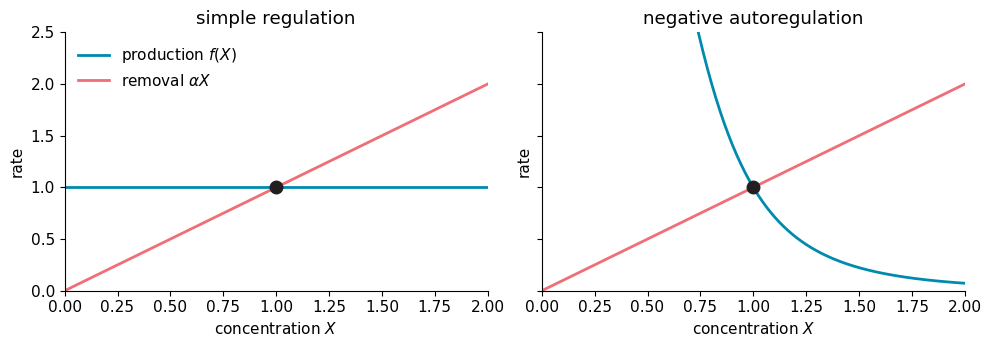

simple: fixed point X* = 1.000, stable
NAR   : fixed point X* = 1.000, stable


In [4]:
alpha = 1.0

def f_simple(X):
    '''Simple regulation: production beta = 1, whatever X is.'''
    return 1.0 * np.ones_like(X)

def f_nar(X, beta=7.0, K=0.6389, n=4):
    '''Negative autoregulation, as in Lecture 2.'''
    return beta * K**n / (K**n + X**n)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
rate_plot(a1, f_simple, alpha, 2, "simple regulation")
rate_plot(a2, f_nar, alpha, 2, "negative autoregulation")
a1.set_ylim(0, 2.5); a1.legend(frameon=False)
plt.tight_layout(); plt.show()

for name, f in [("simple", f_simple), ("NAR", f_nar)]:
    for x in fixed_points(f, alpha, 5):
        print(f"{name:6s}: fixed point X* = {x:.3f}, "
              f"{'stable' if is_stable(f, alpha, x) else 'unstable'}")

---
## 2. How fast does a stable point pull back?

The rate plot says *whether* $X$ returns to a fixed point $X^*$. To say *how fast*, look at a
small displacement $\delta = X - X^*$. Close to $X^*$ the production curve is almost a straight
line, $f(X) \simeq f(X^*) + f'(X^*)\,\delta$, and since $f(X^*) = \alpha X^*$,

$$\frac{d\delta}{dt} = f(X) - \alpha X \simeq -\big(\alpha - f'(X^*)\big)\,\delta .$$

This is the equation of Lecture 1 with $\beta = 0$: the displacement decays exponentially, at the
**relaxation rate**

$$\boxed{\;\lambda = \alpha - f'(X^*)\;}$$

- simple regulation: $f' = 0$, so $\lambda = \alpha$ --- the result of Lecture 1;
- self-**repression**: $f' < 0$, so $\lambda > \alpha$ --- faster;
- self-**activation**: $f' > 0$, so $\lambda < \alpha$ --- slower; and if $f'$ reaches $\alpha$
  the point stops being stable.

To compare fairly we add a self-activating gene with the same steady state $X_{\text{st}} = 1$
and the same $\alpha$: $f(X) = \beta_0 + \beta X/(K + X)$ with $K = 1$, $\beta = 1.6$,
$\beta_0 = 0.2$, so that $f(1) = 0.2 + 0.8 = 1$.

**PREDICT** (pre-read question 4): push each of the three genes 20% above its steady state and let
it go. Which comes back fastest, which slowest?

fixed points of the self-activating gene: [1.0]
negative autoregulation : f'(X*) = -3.428   relaxation rate alpha - f' = 4.428
simple regulation       : f'(X*) = +0.000   relaxation rate alpha - f' = 1.000
positive autoregulation : f'(X*) = +0.400   relaxation rate alpha - f' = 0.600


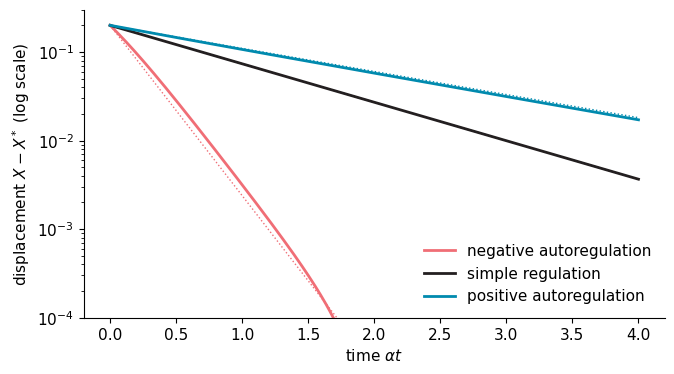

In [5]:
def slope(f, x, h=1e-6):
    '''Numerical derivative f'(x), from two nearby points.'''
    return (f(x + h) - f(x - h)) / (2 * h)

def f_par(X, beta0=0.2, beta=1.6, K=1.0):   # positive autoregulation, n = 1, X_st = 1
    return beta0 + beta * X / (K + X)

print("fixed points of the self-activating gene:", [round(x, 3) for x in fixed_points(f_par, alpha, 5)])

t = np.linspace(0, 4, 400)
plt.figure(figsize=(7.5, 4))
for name, f, col in [("negative autoregulation", f_nar, CORAL),
                     ("simple regulation", f_simple, INK),
                     ("positive autoregulation", f_par, BLUE)]:
    sol = solve_ivp(lambda t, y: [f(y[0]) - alpha * y[0]], [0, 4], [1.2],
                    t_eval=t, rtol=1e-10, atol=1e-12)
    delta = sol.y[0] - 1.0
    lam = alpha - slope(f, 1.0)
    plt.semilogy(t, delta, color=col, lw=2, label=name)
    plt.semilogy(t, 0.2 * np.exp(-lam * t), color=col, lw=1, ls=":")
    print(f"{name:24s}: f'(X*) = {slope(f, 1.0):+.3f}   relaxation rate alpha - f' = {lam:.3f}")
plt.ylim(1e-4, 0.3)
plt.xlabel(r"time $\alpha t$"); plt.ylabel(r"displacement $X - X^*$ (log scale)")
plt.legend(frameon=False); plt.show()

On a logarithmic axis an exponential decay is a straight line, and its slope is the relaxation
rate. The full curves (the exact solution) are close to the dotted lines (the prediction
$0.2\,e^{-\lambda t}$). The self-repressing gene departs from its line at the start, because a
20% displacement is not small for a curve as steep as its $f$.

So the answer to question 4 is one formula: **self-activation is slower than simple regulation**
because its production rises with $X$, which partly cancels the removal. Alon makes the same point
with the gap between the curves (Figure 5.3): near the fixed point the gap is narrower for
self-activation, and the gap is the speed.

(For the self-repressing gene the rate is $4.43$, the same factor $1 + n\theta$ that appeared in
the robustness calculation of Lecture 2, Section 7. This is not a coincidence: both measure how
steeply production falls when $X$ rises.)

---
## 3. Positive autoregulation: one steady state, or two?

Now the self-activating gene of the pre-read, with a small basal production $\beta_0$:

$$f(X) = \beta_0 + \beta\,\frac{X^n}{K^n + X^n},
\qquad \beta_0 = 0.05,\quad \beta = 2,\quad K = 1,\quad \alpha = 1 .$$

**PREDICT** (pre-read questions 1 and 2): how many fixed points for $n = 1$? For $n = 4$? Which
are stable?

n = 1: X* = 1.096 (stable)
n = 4: X* = 0.050 (stable), X* = 0.952 (unstable), X* = 1.910 (stable)


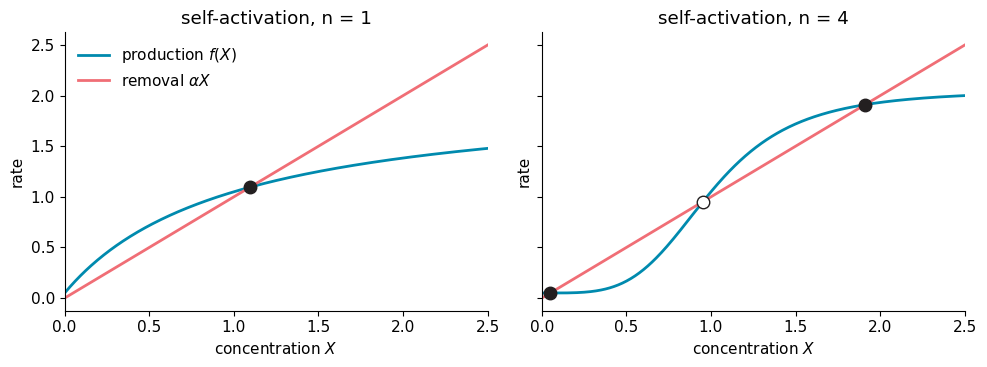

In [6]:
def f_auto(X, n, beta=2.0, beta0=0.05, K=1.0, s=0.0):
    '''Self-activation with basal production beta0 and an external signal s (Section 4).'''
    return beta0 + s + beta * X**n / (K**n + X**n)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, n in zip(axes, [1, 4]):
    f = lambda X, n=n: f_auto(X, n)
    rate_plot(ax, f, alpha, 2.5, f"self-activation, n = {n}")
    points = fixed_points(f, alpha, 10)
    kinds = ["stable" if is_stable(f, alpha, x) else "unstable" for x in points]
    print(f"n = {n}: " + ", ".join(f"X* = {x:.3f} ({k})" for x, k in zip(points, kinds)))
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**$n = 1$: one crossing.** The curve $\beta X/(K+X)$ bends downwards everywhere (it is concave).
It starts above the line, because $f(0) = \beta_0 > 0$, and ends below it, because it saturates
at $\beta_0 + \beta$ while the line keeps rising. A curve that bends only downwards can cross a
straight line from above only once. One fixed point, stable.

**$n = 4$: three crossings.** The curve is now an S: flat near zero, steep around $K$, flat again.
It starts above the line (at $\beta_0$), dips below it, rises above it around $K$, and falls below
it again for good. Three fixed points:

- $X_{\text{low}} = 0.050$, stable --- the gene is essentially **off**, held there by basal
  production;
- $X_u = 0.952$, **unstable** --- production crosses removal from below, so a small push in either
  direction grows;
- $X_{\text{high}} = 1.910$, stable --- the gene is **on** and keeps itself on.

Two stable states is called **bistability**. The unstable point between them is a **threshold**:
it separates the values of $X$ that end up off from those that end up on. Cooperativity is
essential --- with $n = 1$ there is no S, and no second state.

**PREDICT:** start the $n = 4$ gene at many different concentrations between 0 and 2.5. What do
the trajectories look like?

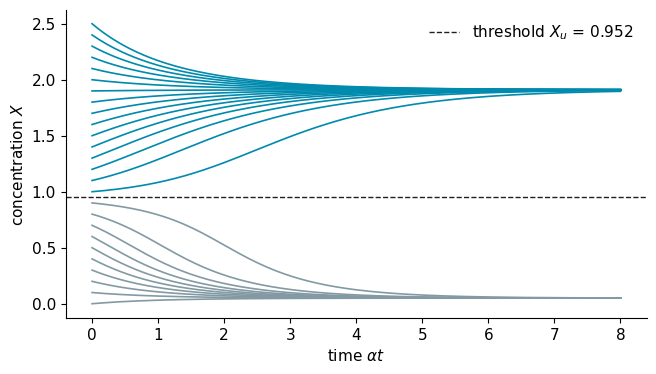

In [7]:
f4 = lambda X: f_auto(X, 4)
X_low, X_u, X_high = fixed_points(f4, alpha, 10)

t = np.linspace(0, 8, 400)
plt.figure(figsize=(7.5, 4))
for X0 in np.linspace(0, 2.5, 26):
    sol = solve_ivp(lambda t, y: [f4(y[0]) - alpha * y[0]], [0, 8], [X0], t_eval=t, rtol=1e-8)
    plt.plot(t, sol.y[0], color=BLUE if X0 > X_u else GREY, lw=1.2)
plt.axhline(X_u, color=INK, ls="--", lw=1, label=f"threshold $X_u$ = {X_u:.3f}")
plt.xlabel(r"time $\alpha t$"); plt.ylabel("concentration $X$"); plt.legend(frameon=False)
plt.show()

Every trajectory that starts above the threshold goes to $X_{\text{high}}$, every one that starts
below goes to $X_{\text{low}}$: two **basins of attraction**, separated by $X_u$ (Alon,
Figure 5.5). Where the gene ends up depends on where it started. That is the beginning of memory.

Notice also the trajectories that start just above or just below $X_u$: they stay close to it for a
long time before moving away. Near the unstable point production and removal almost balance, so
$dX/dt$ is small there.

---
## 4. Memory

Alon's example (Section 5.1.1, Figures 5.6--5.7): a second transcription factor $Y$, switched on
by a signal, also activates $X$. We add its contribution to production as a term $s(t)$:

$$\frac{dX}{dt} = \beta_0 + s(t) + \beta\,\frac{X^n}{K^n + X^n} - \alpha X .$$

The cell starts in the off state, $X_{\text{low}}$. At $t = 2$ the signal switches on; some time
later it switches off again. Three signals:

- $s = 0.5$ for 5 units of time;
- $s = 0.5$ for 3 units of time;
- $s = 0.2$ for 8 units of time.

**PREDICT** (pre-read question 3): where is each cell at $t = 20$?

s = 0.5 for 5: highest X = 1.925, X at t = 20 is 1.910
s = 0.5 for 3: highest X = 0.763, X at t = 20 is 0.050
s = 0.2 for 8: highest X = 0.259, X at t = 20 is 0.050


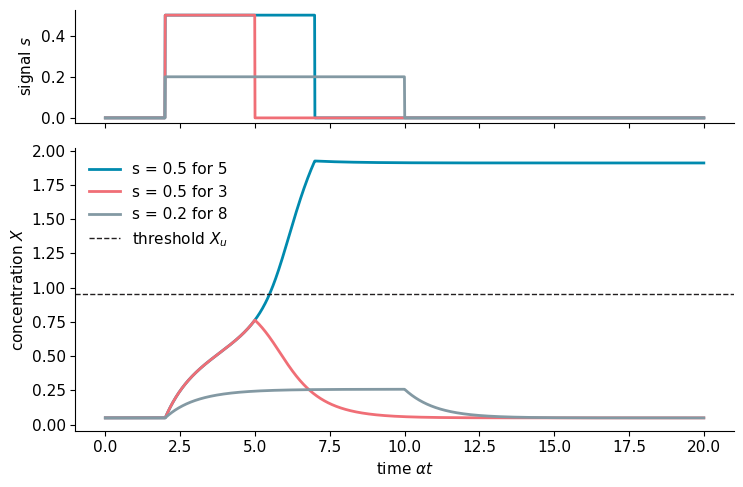

In [8]:
def pulse(t, amplitude, duration, t_on=2.0):
    return amplitude if t_on <= t < t_on + duration else 0.0

t = np.linspace(0, 20, 2000)
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7.5, 5), sharex=True,
                                  gridspec_kw={"height_ratios": [1, 2.5]})
for amplitude, duration, col in [(0.5, 5, BLUE), (0.5, 3, CORAL), (0.2, 8, GREY)]:
    rhs = lambda t, y: [f_auto(y[0], 4, s=pulse(t, amplitude, duration)) - alpha * y[0]]
    sol = solve_ivp(rhs, [0, 20], [X_low], t_eval=t, max_step=0.01)
    top.plot(t, [pulse(ti, amplitude, duration) for ti in t], color=col, lw=2)
    bottom.plot(t, sol.y[0], color=col, lw=2, label=f"s = {amplitude} for {duration}")
    print(f"s = {amplitude} for {duration}: highest X = {sol.y[0].max():.3f}, "
          f"X at t = 20 is {sol.y[0][-1]:.3f}")
bottom.axhline(X_u, color=INK, ls="--", lw=1, label="threshold $X_u$")
top.set_ylabel("signal $s$")
bottom.set(xlabel=r"time $\alpha t$", ylabel="concentration $X$")
bottom.legend(frameon=False); plt.tight_layout(); plt.show()

With $s = 0.5$ for 5 units of time the signal pushes $X$ past the threshold; when the signal
disappears, $X$ does not come back down: it is in the basin of $X_{\text{high}}$ and stays on.
**The cell remembers a signal that is gone.**

The same signal for 3 units of time is not enough: $X$ was still below the threshold when the
signal stopped, so it falls back. And $s = 0.2$ never switches the cell, however long it lasts.
So a signal must be **strong enough and last long enough** --- the two are separate conditions.

This is how a cell can make a decision that outlasts its cause. Alon's example is the muscle
transcription factor **myoD**: once activated it keeps itself on, and the cell keeps its muscle
identity.

### Why $s = 0.2$ is never enough

The grey cell above received $s = 0.2$ for 8 units of time and did not switch. Would 80 units of
time have been enough? No --- and we can see why without running anything longer.

**The idea.** While the signal is on, $s$ is just a constant, so the equation is again of our usual
form, production minus removal:

$$\frac{dX}{dt} = \underbrace{\beta_0 + s + \beta\,\frac{X^n}{K^n + X^n}}_{\text{new production}} - \alpha X .$$

The signal **lifts the production curve by $s$**; the removal line does not move. So we can draw
the rate plot of Section 1 again, once for each value of $s$, and read off the fixed points.

**PREDICT:** the production curve is lifted by $s = 0.2$, then by $s = 0.4$. Does the low crossing
survive?

s = 0.0: fixed points 0.050, 0.952, 1.910
s = 0.2: fixed points 0.259, 0.770, 2.163
s = 0.4: fixed points 2.391


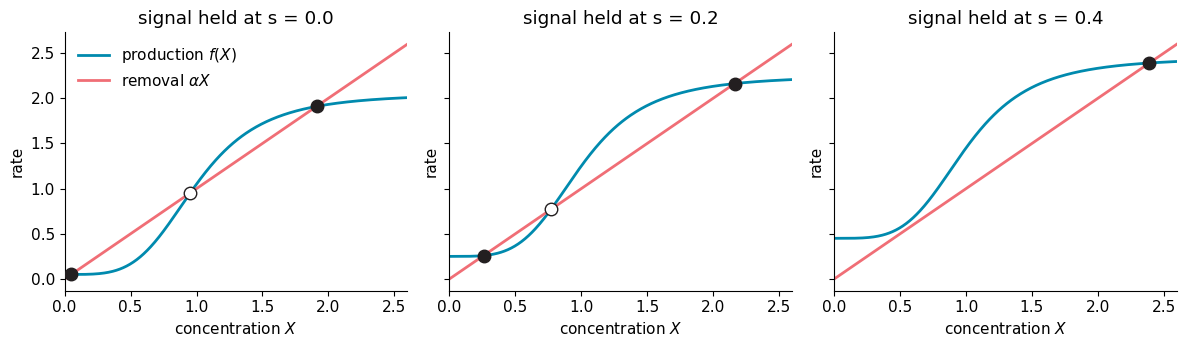

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, s in zip(axes, [0.0, 0.2, 0.4]):
    f = lambda X, s=s: f_auto(X, 4, s=s)              # production with the signal held at s
    rate_plot(ax, f, alpha, 2.6, f"signal held at s = {s}")
    print(f"s = {s}: fixed points " + ", ".join(f"{x:.3f}" for x in fixed_points(f, alpha, 10)))
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

How to read the three panels:

- **$s = 0$**: the three crossings we already know; the cell sits at the low one, 0.050.
- **$s = 0.2$**: the curve is higher, but it still crosses the line three times. There is still a
  low stable point, now at 0.259. The cell climbs to it and **stops**: there $dX/dt = 0$, so
  waiting longer changes nothing. (0.259 is exactly the highest value the grey cell reached.) When
  the signal disappears, the cell slides back to 0.050.
- **$s = 0.4$**: the low and middle crossings have **merged and disappeared**. Only the high
  crossing is left, so the cell must climb towards it. If the signal lasts long enough for $X$ to
  pass the old threshold, the cell stays on when the signal goes --- this is the "long enough"
  condition.

So the question "how strong is strong enough?" becomes: **at which value of $s$ does the low
crossing disappear?** We can find it by raising $s$ in small steps and counting the fixed points.

In [10]:
for s in np.arange(0, 0.6, 0.001):
    points = fixed_points(lambda X: f_auto(X, 4, s=s), alpha, 10)
    if len(points) == 1:                              # the low crossing has gone
        print(f"the low fixed point disappears at s = {s:.3f}")
        break

the low fixed point disappears at s = 0.334


Below $s \simeq 0.334$ a low steady state exists, and a cell that starts off goes to it and waits
there, **however long the signal lasts**. Above it, there is no low state left, and only the
duration matters. That is why "strong enough" and "long enough" are two separate conditions.

### Raising and lowering the signal slowly: hysteresis

Now do the experiment in both directions. Hold $s$ at a value, let $X$ settle, raise $s$ a little,
let $X$ settle again starting from where it was, and so on.

**PREDICT:** slowly raise $s$ from 0 to 0.6, then lower it back to 0. Does $X$ retrace its path?

beta = 2.0: switches ON at s = 0.335;  back at s = 0, X = 1.910 (on)


beta = 1.5: switches ON at s = 0.380;  back at s = 0, X = 0.050 (off)
            switches OFF at s = 0.130


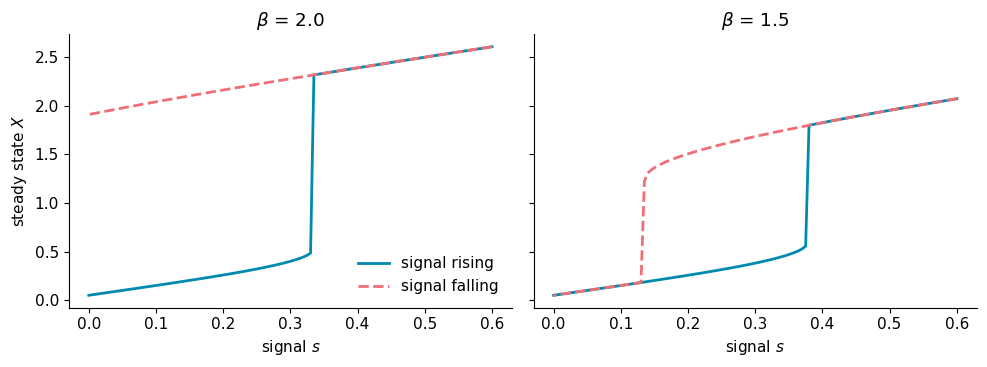

In [11]:
def sweep(beta, s_values, X_start):
    '''Raise or lower s slowly: at each value, let X settle, starting from where it was.'''
    X, out = X_start, []
    for s in s_values:
        rhs = lambda t, y: [f_auto(y[0], 4, beta=beta, s=s) - alpha * y[0]]
        X = solve_ivp(rhs, [0, 60], [X], rtol=1e-8).y[0][-1]
        out.append(X)
    return np.array(out)

s_up = np.linspace(0, 0.6, 121)
s_down = s_up[::-1]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, beta in zip(axes, [2.0, 1.5]):
    X0 = fixed_points(lambda X: f_auto(X, 4, beta=beta), alpha, 10)[0]
    up = sweep(beta, s_up, X0)
    down = sweep(beta, s_down, up[-1])
    ax.plot(s_up, up, color=BLUE, lw=2, label="signal rising")
    ax.plot(s_down, down, color=CORAL, lw=2, ls="--", label="signal falling")
    ax.set(xlabel="signal $s$", title=fr"$\beta$ = {beta}")
    on = s_up[np.argmax(up > 1)]
    print(f"beta = {beta}: switches ON at s = {on:.3f};  "
          f"back at s = 0, X = {down[-1]:.3f} ({'on' if down[-1] > 1 else 'off'})")
    if (down < 1).any():
        print(f"            switches OFF at s = {s_down[np.argmax(down < 1)]:.3f}")
axes[0].set_ylabel("steady state $X$"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

The path depends on the direction. Going up, $X$ stays on the low branch until the low fixed point
disappears --- at the value we just found, $s \simeq 0.33$ (the sweep moves in steps of 0.005) ---
then jumps. Going down, it stays on the high branch. This is called **hysteresis**.

- With $\beta = 2$ (left) the high branch survives all the way to $s = 0$: once switched on, the
  gene **never** switches off by removing the signal. It stays **locked on**, like myoD --- an
  irreversible decision.
- With $\beta = 1.5$ (right) the high branch ends at a positive signal: the gene switches off again,
  but at a **lower** signal than the one that switched it on. Between the two values the state
  depends on the history. A switch with two different thresholds does not flicker when the signal
  hovers near one of them.

Both behaviours come from the same circuit; one parameter decides which.

### All the rate plots in one picture

The sweep only shows where the cell **is**. To see **why** it jumps, go back to the rate plots: for
each value of $s$, draw one rate plot, find its crossings, and mark them above that value of $s$ ---
filled for stable, open for unstable. Each vertical line in the new picture is one rate plot seen
from the side; the dotted lines are the three rate plots drawn above ($s = 0$, 0.2, 0.4).

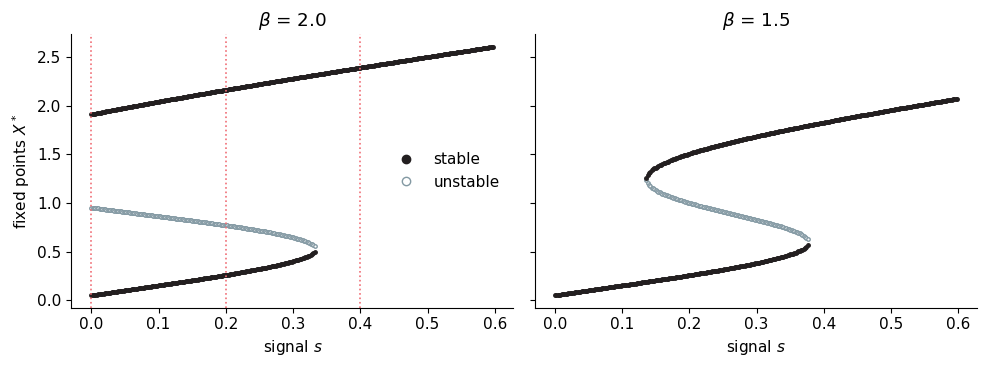

In [12]:
s_grid = np.arange(0, 0.6, 0.002)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, beta in zip(axes, [2.0, 1.5]):
    for s in s_grid:                                   # one rate plot per value of s
        f = lambda X: f_auto(X, 4, beta=beta, s=s)
        for x in fixed_points(f, alpha, 10):            # its crossings, placed above s
            if is_stable(f, alpha, x):
                ax.plot(s, x, "o", ms=2.5, color=INK)
            else:
                ax.plot(s, x, "o", ms=2.5, color=GREY, mfc="white")
    ax.set(xlabel="signal $s$", title=fr"$\beta$ = {beta}")
for s in [0.0, 0.2, 0.4]:
    axes[0].axvline(s, color=CORAL, ls=":", lw=1.2)
axes[0].set_ylabel("fixed points $X^*$")
axes[0].plot([], [], "o", color=INK, label="stable")
axes[0].plot([], [], "o", color=GREY, mfc="white", label="unstable")
axes[0].legend(frameon=False, loc="center right")
plt.tight_layout(); plt.show()

How to read it, left panel ($\beta = 2$):

- On the dotted line at $s = 0$ there are three points: 0.050, 0.952, 1.910 --- the three crossings
  of the first rate plot. At $s = 0.2$, three again; at $s = 0.4$, only the high one.
- As $s$ grows, the **low stable branch** and the **unstable branch** (the threshold) move towards
  each other and meet at $s \simeq 0.334$. There they disappear together: this is the moment the
  low crossing vanished from the rate plot. A cell on the low branch has nowhere to stay and
  **jumps up** to the high branch --- the jump of the sweep.
- The high branch continues all the way to $s = 0$. Going back down there is no place where it
  ends, so there is no jump down: the cell stays on.

Right panel ($\beta = 1.5$): the high branch now also ends, where it meets the unstable branch at a
positive signal. That is where the falling sweep jumped down. Between the two ends both stable
branches exist, and which one the cell is on depends on where it came from: that is the
hysteresis, seen as the fixed points of the rate plots.

The sweep curves of the previous figure lie exactly on the filled branches: a slow sweep simply
follows a stable fixed point until it disappears.

### The hysteresis loop as a film

The last two figures show the same experiment from two sides: the sweep says where the cell
**is**, the picture of the branches says **why**. A film puts them next to each other. We repeat
the slow sweep --- raise $s$ in steps of 0.02 up to 0.6, then lower it back, letting $X$ settle at
each step --- and at every step we draw:

- **left**, the rate plot at the current value of $s$: production (blue; the pale curve is the
  production at $s = 0$, for reference), removal (red), the crossings (filled = stable, open =
  unstable), and the **cell** as a yellow diamond on the $X$ axis. The yellow bar above the cell
  joins removal to production: its length is production minus removal, which is $dX/dt$;
- **right**, the branches of fixed points of the previous figure, with the path the cell has
  followed so far.

Each frame shows the cell **after it has settled** at that value of $s$ (the title says
"steady state"), except at a jump: when the cell's crossing disappears, the film **holds $s$
fixed** and shows the cell moving to the crossing that is left, **in time** (the title shows a
clock, $t$, counted from the moment $s$ reached that value). So the frames are not evenly spaced
in time: the signal changes much more slowly than the cell relaxes, and the cell's own dynamics
only become visible when the crossing it was following disappears.

**PREDICT:** in the left panel, what happens to the low crossing just before the cell jumps? Where
does the cell move slowly, and where fast?

In [13]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

GOLD = "#F5A623"
plt.rcParams.update({"animation.embed_limit": 50,           # MB allowed in the notebook
                     "animation.frame_format": "jpeg"})     # lighter than png

def film(beta, s_max=0.6, ds=0.02, X_max=2.6):
    '''Raise s in steps of ds from 0 to s_max and back, letting X settle at each step,
    and draw the rate plot at every step. When the cell jumps, hold s and film the jump.'''
    # 1. the frames: one per value of s, plus extra frames while the cell is jumping
    s_up = np.arange(0, s_max + ds / 2, ds)
    s_values = np.concatenate([s_up, s_up[-2::-1]])           # up, then back down
    X = fixed_points(lambda Y: f_auto(Y, 4, beta=beta), alpha, 10)[0]
    frames = []                                                # (s, X, rising?, t or None)
    for k, s in enumerate(s_values):
        rising = k < len(s_up)
        rhs = lambda t, y: [f_auto(y[0], 4, beta=beta, s=s) - alpha * y[0]]
        sol = solve_ivp(rhs, [0, 60], [X], dense_output=True, rtol=1e-8)
        X_end = sol.y[0][-1]
        if abs(X_end - X) > 0.1:                               # a jump: film the cell moving
            print(f"beta = {beta}: jump {'up' if rising else 'down'} at s = {s:.2f}, "
                  f"from X = {X:.3f} to X = {X_end:.3f}")
            for t in np.linspace(0, 10, 18):
                frames.append((s, sol.sol(t)[0], rising, t))
        X = X_end
        frames.append((s, X, rising, None))            # settled

    # 2. the branches of fixed points, as in the previous figure
    branch = []
    for sb in np.arange(0, s_max + 1e-9, 0.002):
        f = lambda Y: f_auto(Y, 4, beta=beta, s=sb)
        branch += [(sb, x, is_stable(f, alpha, x)) for x in fixed_points(f, alpha, X_max)]
    branch = np.array(branch)

    # 3. the figure: rate plot on the left, fixed points against s on the right
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9), dpi=72)
    Xg = np.linspace(0, X_max, 300)
    left.plot(Xg, f_auto(Xg, 4, beta=beta), color=BLUE, lw=1, alpha=0.3)   # s = 0, for reference
    left.plot(Xg, alpha * Xg, color=CORAL, lw=2, label=r"removal $\alpha X$")
    curve, = left.plot([], [], color=BLUE, lw=2, label="production $f(X) + s$")
    stable, = left.plot([], [], "o", ms=9, color=INK, zorder=5)
    unstable, = left.plot([], [], "o", ms=9, color=INK, mfc="white", zorder=5)
    gap, = left.plot([], [], color=GOLD, lw=4, solid_capstyle="butt", zorder=4)
    cell_left, = left.plot([], [], "D", ms=10, color=GOLD, mec=INK, zorder=6, clip_on=False)
    left.set(xlim=(0, X_max), ylim=(0, 2.9), xlabel="concentration $X$", ylabel="rate")
    left.legend(frameon=False, loc="upper left", fontsize=9)

    on, off = branch[branch[:, 2] == 1], branch[branch[:, 2] == 0]
    right.plot(on[:, 0], on[:, 1], "o", ms=2, color=INK)
    right.plot(off[:, 0], off[:, 1], "o", ms=2, color=GREY, mfc="white")
    path, = right.plot([], [], color=GOLD, lw=2)
    cell_right, = right.plot([], [], "D", ms=9, color=GOLD, mec=INK, zorder=6)
    s_line = right.axvline(0, color=CORAL, ls=":", lw=1.2)
    right.set(xlim=(0, s_max), ylim=(0, X_max), xlabel="signal $s$",
              ylabel="concentration $X$", title=fr"$\beta$ = {beta}")
    plt.tight_layout()

    def draw(k):
        s, X, rising, t = frames[k]
        f = lambda Y: f_auto(Y, 4, beta=beta, s=s)
        curve.set_data(Xg, f(Xg))
        points = fixed_points(f, alpha, X_max)
        good = [x for x in points if is_stable(f, alpha, x)]
        bad = [x for x in points if not is_stable(f, alpha, x)]
        stable.set_data(good, alpha * np.array(good))
        unstable.set_data(bad, alpha * np.array(bad))
        gap.set_data([X, X], [alpha * X, f(X)])                # production minus removal = dX/dt
        cell_left.set_data([X], [0])
        path.set_data([fr[0] for fr in frames[:k + 1]], [fr[1] for fr in frames[:k + 1]])
        cell_right.set_data([s], [X])
        s_line.set_xdata([s, s])
        if t is None:
            left.set_title(f"s = {s:.2f}, {'rising' if rising else 'falling'}: steady state")
        else:
            left.set_title(f"s held at {s:.2f}: time t = {t:.1f}")

    anim = FuncAnimation(fig, draw, frames=len(frames), interval=200)
    plt.close(fig)                                             # show the film, not a still
    return HTML(anim.to_jshtml(default_mode="once"))

film(2.0)

beta = 2.0: jump up at s = 0.34, from X = 0.446 to X = 2.324


Press play, or drag the slider to go back and forth. What to look for ($\beta = 2$):

- **Rising, $s$ from 0 to 0.32.** The blue curve is lifted; the low (filled) and middle (open)
  crossings slide towards each other. The cell follows the low one, and the yellow bar has zero
  length every time the cell has settled: it sits at a fixed point.
- **$s = 0.34$, held (the frames with a clock).** The two crossings have touched and disappeared --- this is the step just
  past $s \simeq 0.334$, where the low fixed point disappears. Production is now above removal
  for every $X$ up to the high crossing, so the cell **must** climb. It climbs slowly at first,
  where the blue curve passes just above the red line (the bar is short: $dX/dt$ is small), then
  fast, then slowly again as it reaches the high crossing. In the right panel this is the vertical
  jump.
- **Falling, back to $s = 0$.** The high crossing moves down but never disappears, so the cell
  rides it all the way back. At $s = 0$ the rate plot is the same as at the start --- three
  crossings --- but the cell is on the other stable one. Same rate plot, different cell: that is
  the memory.

Now the gene with $\beta = 1.5$, whose loop closes.

**PREDICT:** on the way down, which crossing disappears, and what does the rate plot look like at
that moment?

In [14]:
film(1.5)

beta = 1.5: jump up at s = 0.38, from X = 0.495 to X = 1.799
beta = 1.5: jump down at s = 0.12, from X = 1.308 to X = 0.171


- **Rising**: the same story as before, with the jump up at $s = 0.38$ (the low fixed point
  disappears at $s \simeq 0.378$).
- **Falling**: now it is the **high** crossing that meets the middle one --- the top of the S
  touches the red line from above --- and they disappear together just below $s \simeq 0.136$.
  At $s = 0.12$ production is below removal for every $X$ down to the low crossing, so the cell
  must fall.
- Between 0.136 and 0.378 the rate plot has three crossings both on the way up and on the way down;
  the cell is on the low one going up and on the high one going down. The rate plot alone does not
  say where the cell is --- its **history** does.

Every jump has the same cause: **a stable crossing and the unstable one meet and disappear
together**, and the cell has to move to the crossing that is left.

---
### What we did

- The **rate plot** gives the fixed points and their stability without solving anything; the
  slope rule $f'(X^*) < \alpha$ says the same in one line.
- The **relaxation rate** $\alpha - f'(X^*)$ explains in one formula why self-repression is fast
  and self-activation slow.
- **Self-activation with cooperativity** ($n \geq 2$) can have **two stable states**, separated by
  an unstable threshold; with $n = 1$ it cannot.
- Two stable states give **memory**: a transient signal can switch the gene on for good, and the
  response to a signal depends on its history (**hysteresis**).

**Looking ahead.** Everything here was deterministic: a cell sitting at $X_{\text{low}}$ stays
there forever unless a signal comes. Real cells hold a few tens of molecules, and production and
removal happen one event at a time. What does that do to a cell sitting next to a threshold?